In [1]:
import matplotlib.pylab as plt 
%matplotlib inline
import numpy as np
import rubin_sim.splat as splat
import pandas as pd
import sqlite3
import healpy as hp
import copy
import datetime
import os

from rubin_sim.splat.plots import bright_filter_colors

from rubin_scheduler.utils import (
    angular_separation,
    ddf_locations,hpid2_ra_dec)

from rubin_sim.data import get_baseline
from os.path import basename



In [2]:
# Read in the current baseline simulation
db_file = "horseshoe_v5.3.7_10yrs.db"
data_source = basename(db_file).replace('.db', '')
con = sqlite3.connect(db_file)
df = pd.read_sql('select * from observations;', con)
con.close()
# Convert to a numpy array
visits_array = df.to_records(index=False)



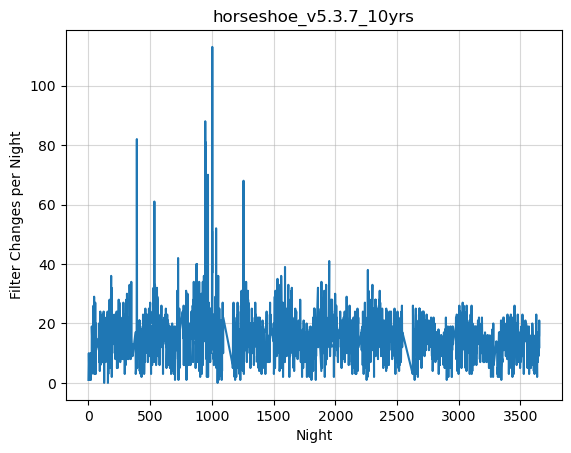

In [4]:
# If we want to compute something per night, use pandas group by
info = {"data_source": data_source, "name": "filter changes"}
fpn = df.groupby("night")["filter"].apply(splat.count_value_changes)
pl = splat.PlotLine(info=info)
fig = pl(fpn.index, fpn.values, xlabel="Night", ylabel="Filter Changes per Night")


In [14]:
fpn.index[(np.where(fpn.values > 60))]

Index([393, 535, 947, 948, 949, 969, 1004, 1257], dtype='int64', name='night')

In [19]:
indx = np.where(visits_array["night"] == 969)[0]
visits_array["scheduler_note"][indx]

array(['ToO, GW_case_B_C, r, 460, i3, 60574;hs_avoid',
       'ToO, GW_case_B_C, r, 460, i3, 60622;hs_avoid',
       'ToO, GW_case_B_C, r, 460, i4, 60693',
       'ToO, GW_case_B_C, r, 460, i4, 60694',
       'ToO, GW_case_B_C, r, 460, i4, 60695',
       'ToO, GW_case_B_C, r, 460, i4, 60696',
       'ToO, GW_case_B_C, r, 460, i4, 60697',
       'ToO, GW_case_B_C, r, 460, i4, 60698',
       'ToO, GW_case_B_C, r, 460, i4, 60699',
       'ToO, GW_case_B_C, r, 460, i4, 60700',
       'ToO, GW_case_B_C, r, 460, i4, 60701',
       'ToO, GW_case_B_C, r, 460, i4, 60702',
       'ToO, GW_case_B_C, r, 460, i4, 60703',
       'ToO, GW_case_B_C, r, 460, i4, 60704',
       'ToO, GW_case_B_C, r, 460, i4, 60705',
       'ToO, GW_case_B_C, r, 460, i4, 60706',
       'ToO, GW_case_B_C, r, 460, i4, 60707',
       'ToO, GW_case_B_C, r, 460, i4, 60708',
       'ToO, GW_case_B_C, r, 460, i4, 60709',
       'ToO, GW_case_B_C, r, 460, i4, 60710',
       'ToO, GW_case_B_C, r, 460, i4, 60711',
       'ToO, GW_

In [18]:
np.sum(visits_array["band"][indx][1:] != visits_array["band"][indx][:-1])

np.int64(70)